Load the spreadsheet into Python

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_excel("P1_WBM_Database_4PAPERS.xlsx", sheet_name="Data", header=1)
df = df[df["Sample_ID"].notna()]

print(df.shape)
df.head()

(71, 34)


,Sample_ID,Source_ID,Clay_deposit,Clay_category,Beneficiation_method,Beneficiant_conc_wt_pct,Additive_name,Additive_conc_ppb,Clay_conc_g_per_350mL,API_basis,...,pH,Mud_density_ppg,Chk_Dial600,Chk_YP_PV,Chk_Filtrate,API_Overall,Notes,Additive_2_name,Additive_2_conc_ppb,Benef_aging_hr
1,S02-00,S02,"Gombe (Filia/Cham, Dongaje)",Beneficiated local,Sodium bicarbonate (NaHCO3),NaN,NaN,0.00,17.5,NaN,...,7.35,8.6,NaN,NaN,NaN,NaN,"Base fluid, Mud beneficiation section. PV 5, Y...",NaN,NaN,NaN
2,S02-01,S02,"Gombe (Filia/Cham, Dongaje)",Beneficiated local,Sodium bicarbonate (NaHCO3),NaN,Fgum,4.00,17.5,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,"Table 6 (30 C), run 1. Additive labels as prin...",Ufor,5.0,NaN
3,S02-02,S02,"Gombe (Filia/Cham, Dongaje)",Beneficiated local,Sodium bicarbonate (NaHCO3),NaN,Fgum,2.75,17.5,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,"Table 6 (30 C), run 2. Additive labels as prin...",Ufor,5.0,NaN
4,S02-03,S02,"Gombe (Filia/Cham, Dongaje)",Beneficiated local,Sodium bicarbonate (NaHCO3),NaN,Fgum,2.75,17.5,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,"Table 6 (30 C), run 3. Additive labels as prin...",Ufor,3.5,NaN
5,S02-04,S02,"Gombe (Filia/Cham, Dongaje)",Beneficiated local,Sodium bicarbonate (NaHCO3),NaN,Fgum,2.75,17.5,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,"Table 6 (30 C), run 4. Additive labels as prin...",Ufor,2.0,NaN


Number of rows per paper

In [ ]:
df["Source_ID"].value_counts()

,count
Source_ID,
S01,31
S02,28
S04,7
S03,5


Number of rows per clay type

In [ ]:
df["Clay_category"].value_counts()

,count
Clay_category,
Beneficiated local,66
Raw local,3
Imported reference,2


Chart 1: Fluid loss before and after beneficiation

In [ ]:
import matplotlib.pyplot as plt

reduction per deposit (%): [np.float64(82.1), np.float64(81.2), np.float64(59.0)]
treated values: [np.float64(17.5), np.float64(22.5), np.float64(49.0)] | all above 15 mL: True


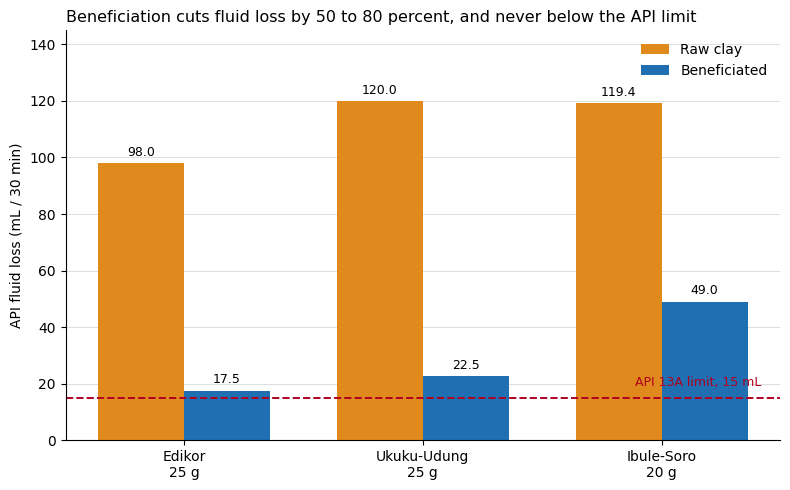

In [ ]:
d = df.set_index("Sample_ID")

pairs = [("Edikor\n25 g", "S03-01", "S03-02"),
         ("Ukuku-Udung\n25 g", "S03-03", "S03-04"),
         ("Ibule-Soro\n20 g", "S04-02", "S04-03")]

deposits = [p[0] for p in pairs]
raw = [d.loc[p[1], "API_filtrate_mL"] for p in pairs]
treated = [d.loc[p[2], "API_filtrate_mL"] for p in pairs]

# check the title's claims against the data
reductions = [(r - t) / r * 100 for r, t in zip(raw, treated)]
print("reduction per deposit (%):", [round(v, 1) for v in reductions])
print("treated values:", treated, "| all above 15 mL:", all(t > 15 for t in treated))

x = range(len(deposits))
w = 0.36

fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar([i - w/2 for i in x], raw, w, label="Raw clay", color="#E08A1E")
b2 = ax.bar([i + w/2 for i in x], treated, w, label="Beneficiated", color="#1F6FB2")

ax.axhline(15, color="#B00020", linestyle="--", linewidth=1.4)
ax.text(2.42, 19, "API 13A limit, 15 mL", color="#B00020", fontsize=9, ha="right")

ax.bar_label(b1, fmt="%.1f", padding=3, fontsize=9)
ax.bar_label(b2, fmt="%.1f", padding=3, fontsize=9)

ax.set_xticks(list(x))
ax.set_xticklabels(deposits)
ax.set_ylabel("API fluid loss (mL / 30 min)")
ax.set_title("Beneficiation cuts fluid loss by 50 to 80 percent, and never below the API limit",
             loc="left", fontsize=11.5)
ax.set_ylim(0, 145)
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#DDDDDD", linewidth=0.7)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Chart 2: Viscosity against the API standard

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

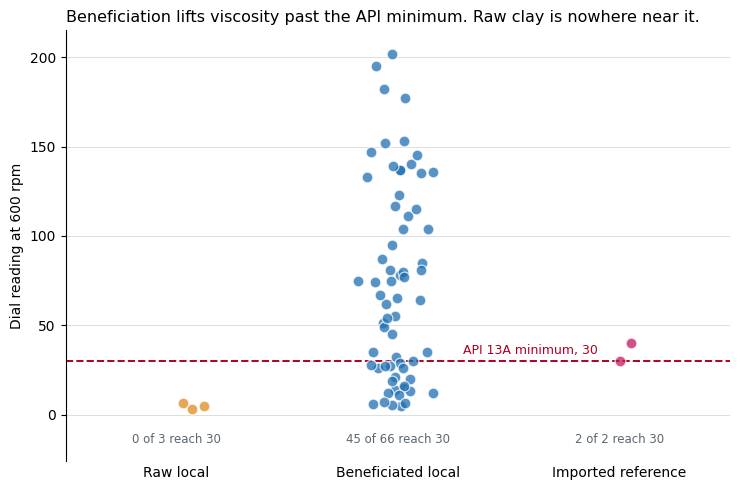

In [ ]:
cats = ["Raw local", "Beneficiated local", "Imported reference"]
colour = {"Raw local": "#E08A1E",
          "Beneficiated local": "#1F6FB2",
          "Imported reference": "#C2185B"}

np.random.seed(0)
fig, ax = plt.subplots(figsize=(7.5, 5))

for i, cat in enumerate(cats):
    vals = df.loc[df["Clay_category"] == cat, "Dial_600"]
    jitter = np.random.normal(0, 0.07, len(vals))
    ax.scatter(i + jitter, vals, s=60, color=colour[cat],
               alpha=0.75, edgecolor="white", linewidth=0.9, zorder=3)
    passed = (vals >= 30).sum()
    ax.text(i, -16, f"{passed} of {len(vals)} reach 30", ha="center",
            fontsize=8.5, color="#5C6670")

ax.axhline(30, color="#B00020", linestyle="--", linewidth=1.4, zorder=2)
ax.text(1.6, 34, "API 13A minimum, 30", color="#B00020", fontsize=9, ha="center")

ax.set_xticks(range(len(cats)))
ax.set_xticklabels(cats)
ax.set_ylabel("Dial reading at 600 rpm")
ax.set_title("Beneficiation lifts viscosity past the API minimum. Raw clay is nowhere near it.",
             loc="left", fontsize=11.5)
ax.set_ylim(-26, 215)
ax.set_xlim(-0.5, 2.5)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.grid(axis="y", color="#DDDDDD", linewidth=0.7, zorder=1)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

Chart 3: Response to soda ash dose, using runs from R.O.Afolabi,et al.,Dataset on the beneficiation of a Nigerian bentonite
clay mineral for drilling mud formulation, Data in Brief (2018), https://doi.org/10.1016/j.
dib.2018.07.071

In [ ]:
#S01-03  104.0
#S01-10  140.0
#S01-15  117.0
#S01-19  153.0
#S01-23  137.0
#S01-25  115.0
#S01-30  147.0

#n = 7   min 104   max 153   spread 49   mean 130.4   sd 18.4

In [ ]:
# soda ash  2 g  → 104.0
# soda ash 10 g  → 135.0
# effect across the full dose range: 31

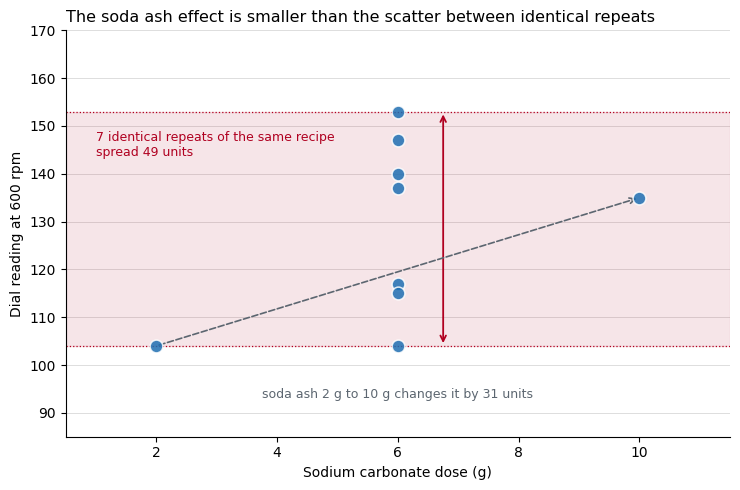

points plotted: 9 | centre spread: 104.0 to 153.0 | soda effect: 31.0


In [ ]:
# Cell 6: does soda ash dose actually move the viscosity?
import matplotlib.pyplot as plt

s1 = df[df["Source_ID"] == "S01"]

# hold everything constant except soda ash
fixed = s1[(s1["Clay_conc_g_per_350mL"] == 30) &
           (s1["Additive_conc_ppb"] == 7.5) &
           (s1["Benef_aging_hr"] == 15)]

soda = fixed["Additive_2_conc_ppb"]
dial = fixed["Dial_600"]

# the centre-point repeats are the noise estimate
ctr = fixed[fixed["Additive_2_conc_ppb"] == 6]["Dial_600"]
lo, hi = ctr.min(), ctr.max()

# soda ash effect, computed from the data instead of typed in
soda_lo, soda_hi = soda.min(), soda.max()
d_lo = fixed.loc[soda == soda_lo, "Dial_600"].mean()
d_hi = fixed.loc[soda == soda_hi, "Dial_600"].mean()
effect = d_hi - d_lo

fig, ax = plt.subplots(figsize=(7.5, 5))

ax.axhspan(lo, hi, color="#B00020", alpha=0.10, zorder=1)
ax.axhline(lo, color="#B00020", linewidth=0.9, linestyle=":", zorder=2)
ax.axhline(hi, color="#B00020", linewidth=0.9, linestyle=":", zorder=2)

ax.scatter(soda, dial, s=85, color="#1F6FB2", alpha=0.85,
           edgecolor="white", linewidth=1.1, zorder=4)

# noise band annotation
ax.annotate("", xy=(6.75, hi), xytext=(6.75, lo),
            arrowprops=dict(arrowstyle="<->", color="#B00020", linewidth=1.3))
ax.text(1.0, 146, f"{len(ctr)} identical repeats of the same recipe\nspread {hi - lo:.0f} units",
        color="#B00020", fontsize=9, va="center", ha="left")

# dose effect annotation
ax.annotate("", xy=(soda_hi, d_hi), xytext=(soda_lo, d_lo),
            arrowprops=dict(arrowstyle="->", color="#5C6670",
                            linewidth=1.2, linestyle="--"))
ax.text((soda_lo + soda_hi) / 2, 93,
        f"soda ash {soda_lo:g} g to {soda_hi:g} g changes it by {effect:.0f} units",
        color="#5C6670", fontsize=9, ha="center")

ax.set_xlabel("Sodium carbonate dose (g)")
ax.set_ylabel("Dial reading at 600 rpm")
ax.set_title("The soda ash effect is smaller than the scatter between identical repeats",
             loc="left", fontsize=11.5)
ax.set_xticks([2, 4, 6, 8, 10])
ax.set_xlim(0.5, 11.5)
ax.set_ylim(85, 170)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#DDDDDD", linewidth=0.7, zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
print("points plotted:", len(fixed), "| centre spread:", lo, "to", hi,
      "| soda effect:", round(effect, 1))

In [ ]:
# Clay category        Rows   On API basis   Reach 30   Filtrate measured   Pass 15 mL
# Beneficiated local     61         0         45 of 61          3                1
# Raw local               2         0          0 of 2           2                0
# Imported reference      1         0          1 of 1           0                0
# All rows               64      0 of 64      46 of 64        5 of 64          1 of 64

In [ ]:
# Cell 7: the summary table
cats = ["Raw local", "Beneficiated local", "Imported reference"]

summary = df.groupby("Clay_category").agg(
    rows=("Sample_ID", "count"),
    on_API_basis=("API_basis", lambda s: (s == "Yes").sum()),
    reach_dial600_30=("Dial_600", lambda s: (s >= 30).sum()),
    filtrate_tested=("API_filtrate_mL", "count"),
    pass_filtrate_15=("API_filtrate_mL", lambda s: (s <= 15).sum()),
).reindex(cats)
print(summary.to_string())

print()
print("TOTAL rows:", len(df))
print("rows on API basis (22.5 g):", (df["API_basis"] == "Yes").sum())
print("clay loadings used:", sorted(df["Clay_conc_g_per_350mL"].dropna().unique()))

                    rows  on_API_basis  reach_dial600_30  filtrate_tested  pass_filtrate_15
Clay_category                                                                              
Raw local              3             0                 0                3                 0
Beneficiated local    66             0                45                8                 1
Imported reference     2             0                 2                1                 1

TOTAL rows: 71
rows on API basis (22.5 g): 0
clay loadings used: [np.float64(17.5), np.float64(20.0), np.float64(25.0), np.float64(30.0), np.float64(35.0), np.float64(40.0)]


samples with both measurements: 12
samples passing both: 1 | ['S04-01'] | ['Imported reference']
points outside the axis limits: []


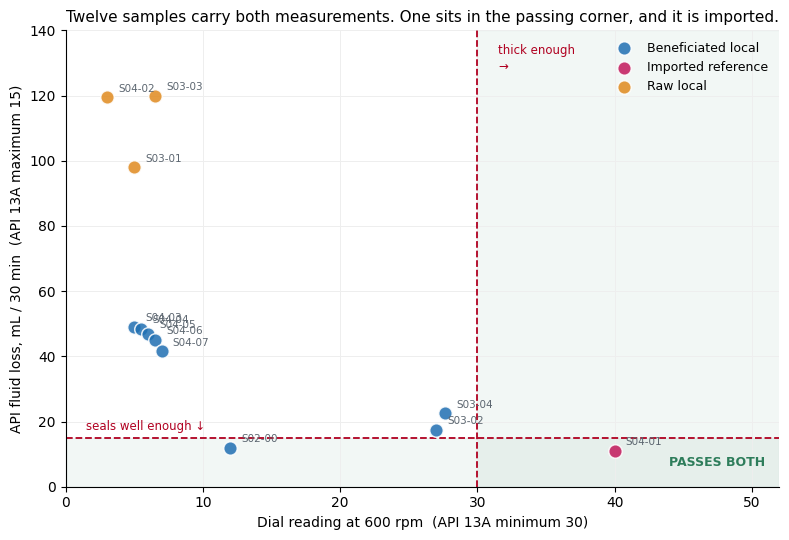

In [ ]:
# Cell 8: chart 4, both tests at once
import matplotlib.pyplot as plt

both = df[df["API_filtrate_mL"].notna() & df["Dial_600"].notna()]

colour = {"Raw local": "#E08A1E",
          "Beneficiated local": "#1F6FB2",
          "Imported reference": "#C2185B"}

# check the title's claims against the data
passing = both[(both["Dial_600"] >= 30) & (both["API_filtrate_mL"] <= 15)]
print("samples with both measurements:", len(both))
print("samples passing both:", len(passing), "|", list(passing["Sample_ID"]),
      "|", list(passing["Clay_category"]))
clipped = both[(both["Dial_600"] > 52) | (both["API_filtrate_mL"] > 140)]
print("points outside the axis limits:", list(clipped["Sample_ID"]))

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.axvspan(30, 150, color="#2E7D5B", alpha=0.06, zorder=0)
ax.axhspan(0, 15, color="#2E7D5B", alpha=0.06, zorder=0)

ax.axvline(30, color="#B00020", linestyle="--", linewidth=1.3, zorder=2)
ax.axhline(15, color="#B00020", linestyle="--", linewidth=1.3, zorder=2)

for cat, grp in both.groupby("Clay_category"):
    ax.scatter(grp["Dial_600"], grp["API_filtrate_mL"], s=95,
               color=colour[cat], alpha=0.85, edgecolor="white",
               linewidth=1.1, label=cat, zorder=4)

for _, r in both.iterrows():
    ax.annotate(r["Sample_ID"], (r["Dial_600"], r["API_filtrate_mL"]),
                textcoords="offset points", xytext=(8, 4),
                fontsize=7.5, color="#5C6670", zorder=5)

ax.text(44, 6.5, "PASSES BOTH", color="#2E7D5B", fontsize=9,
        fontweight="bold", ha="left", zorder=6)
ax.text(31.5, 128, "thick enough\n→", color="#B00020", fontsize=8.5, zorder=6)
ax.text(1.5, 17.5, "seals well enough ↓", color="#B00020", fontsize=8.5, zorder=6)

ax.set_xlabel("Dial reading at 600 rpm  (API 13A minimum 30)")
ax.set_ylabel("API fluid loss, mL / 30 min  (API 13A maximum 15)")
ax.set_title("Twelve samples carry both measurements. One sits in the passing corner, and it is imported.",
             loc="left", fontsize=11)
ax.set_xlim(0, 52)
ax.set_ylim(0, 140)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(color="#EEEEEE", linewidth=0.7, zorder=1)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()